# PON synthetic dataset: per-class statistics and feature-redundancy test

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression

sns.set_theme(style="whitegrid", palette="Set2")
os.makedirs("results", exist_ok=True)
os.makedirs("figures", exist_ok=True)

# >>> Adjust this path to where your CSV is
FILE_PATH = "pon_synthetic_dataset_50000_overlap.csv"

data = pd.read_csv(FILE_PATH)
features = ["packet_size_bytes", "packets_per_sec", "traffic_rate_mbps"]
target = "traffic_type"

print("Shape:", data.shape)
print("\nColumns and types:")
print(data.dtypes)
print("\nMissing values per column:")
print(data.isna().sum())
data.head()

Shape: (50000, 18)

Columns and types:
onu_id                        int64
fiber_length_km             float64
split_ratio                   int64
network_load                float64
packet_size_bytes           float64
packets_per_sec             float64
traffic_rate_mbps           float64
buffer_occupancy            float64
bandwidth_allocated_mbps    float64
queue_delay_ms              float64
latency_ms                  float64
jitter_ms                   float64
received_power_dbm          float64
snr_db                      float64
ber                         float64
traffic_type                    str
congestion                    int64
fault_event                   int64
dtype: object

Missing values per column:
onu_id                      0
fiber_length_km             0
split_ratio                 0
network_load                0
packet_size_bytes           0
packets_per_sec             0
traffic_rate_mbps           0
buffer_occupancy            0
bandwidth_allocated_mbps    0
q

,onu_id,fiber_length_km,split_ratio,network_load,packet_size_bytes,packets_per_sec,traffic_rate_mbps,buffer_occupancy,bandwidth_allocated_mbps,queue_delay_ms,latency_ms,jitter_ms,received_power_dbm,snr_db,ber,traffic_type,congestion,fault_event
0,31,11.92,32,0.303,636.54,172.92,3.643,22.62,3.342,3.432,9.032,0.323,-19.646,24.140,0.000457,web,0,0
1,14,7.26,32,0.552,644.62,206.05,2.632,23.27,3.631,2.237,5.512,0.010,-19.676,23.730,0.000843,gaming,0,0
2,31,18.60,32,0.782,763.99,311.70,6.692,48.29,5.803,5.662,10.224,1.092,-23.048,21.963,0.001354,video,0,0
3,3,19.81,32,0.683,839.98,314.67,5.707,36.98,7.055,4.501,6.713,0.468,-20.313,19.943,0.001934,video,1,0
4,29,16.92,32,0.853,337.31,162.76,1.518,24.91,1.495,4.277,8.676,0.708,-17.669,22.089,0.001650,iot,0,1


## 1. Per-class statistics

In [2]:
# Class balance
counts = data[target].value_counts()
share = (data[target].value_counts(normalize=True) * 100).round(2)
print(pd.DataFrame({"samples": counts, "percent": share}))

# Per-class descriptive statistics
rows = []
for cls, g in data.groupby(target):
    for f in features:
        rows.append({
            "class": cls, "feature": f, "n": len(g),
            "min": g[f].min(), "p5": g[f].quantile(0.05), "median": g[f].median(),
            "mean": g[f].mean(), "std": g[f].std(),
            "p95": g[f].quantile(0.95), "max": g[f].max(),
        })
class_stats = pd.DataFrame(rows).round(3)
class_stats.to_csv("results/class_feature_statistics.csv", index=False)
class_stats

              samples  percent
traffic_type                  
video           16118    32.24
web             14920    29.84
iot              9913    19.83
gaming           9049    18.10


,class,feature,n,min,p5,median,mean,std,p95,max
0,gaming,packet_size_bytes,9049,64.000,319.716,619.310,618.626,181.329,910.518,1361.860
1,gaming,packets_per_sec,9049,43.480,166.230,245.220,245.073,47.664,323.576,437.210
2,gaming,traffic_rate_mbps,9049,1.130,2.792,4.220,4.227,0.879,5.681,7.747
3,iot,packet_size_bytes,9913,64.000,101.480,328.590,330.186,137.029,562.700,874.630
4,iot,packets_per_sec,9913,16.200,69.706,120.660,120.991,31.482,172.484,229.410
5,iot,traffic_rate_mbps,9913,0.050,0.607,1.369,1.364,0.457,2.107,3.195
6,video,packet_size_bytes,16118,161.200,665.815,1020.940,1021.003,214.079,1380.956,1500.000
7,video,packets_per_sec,16118,1.000,182.147,282.730,283.227,62.185,385.847,513.910
8,video,traffic_rate_mbps,16118,0.915,3.730,5.625,5.618,1.157,7.516,10.407
9,web,packet_size_bytes,14920,64.000,417.428,760.520,759.104,207.671,1100.210,1467.760


In [3]:
# Compact table for the paper: mean ± std [p5–p95]
tbl = {}
for cls, g in data.groupby(target):
    tbl[cls] = {f: f"{g[f].mean():.1f} ± {g[f].std():.1f} [{g[f].quantile(.05):.1f}–{g[f].quantile(.95):.1f}]"
                for f in features}
summary_tbl = pd.DataFrame(tbl).T
summary_tbl.insert(0, "samples", counts.reindex(summary_tbl.index))
summary_tbl.to_csv("results/table_class_profiles.csv")
display(summary_tbl)
print(summary_tbl.to_latex())

,samples,packet_size_bytes,packets_per_sec,traffic_rate_mbps
gaming,9049,618.6 ± 181.3 [319.7–910.5],245.1 ± 47.7 [166.2–323.6],4.2 ± 0.9 [2.8–5.7]
iot,9913,330.2 ± 137.0 [101.5–562.7],121.0 ± 31.5 [69.7–172.5],1.4 ± 0.5 [0.6–2.1]
video,16118,1021.0 ± 214.1 [665.8–1381.0],283.2 ± 62.2 [182.1–385.8],5.6 ± 1.2 [3.7–7.5]
web,14920,759.1 ± 207.7 [417.4–1100.2],201.5 ± 51.7 [115.4–286.4],3.4 ± 0.9 [1.8–4.9]


\begin{tabular}{lrlll}
\toprule
 & samples & packet_size_bytes & packets_per_sec & traffic_rate_mbps \\
\midrule
gaming & 9049 & 618.6 ± 181.3 [319.7–910.5] & 245.1 ± 47.7 [166.2–323.6] & 4.2 ± 0.9 [2.8–5.7] \\
iot & 9913 & 330.2 ± 137.0 [101.5–562.7] & 121.0 ± 31.5 [69.7–172.5] & 1.4 ± 0.5 [0.6–2.1] \\
video & 16118 & 1021.0 ± 214.1 [665.8–1381.0] & 283.2 ± 62.2 [182.1–385.8] & 5.6 ± 1.2 [3.7–7.5] \\
web & 14920 & 759.1 ± 207.7 [417.4–1100.2] & 201.5 ± 51.7 [115.4–286.4] & 3.4 ± 0.9 [1.8–4.9] \\
\bottomrule
\end{tabular}



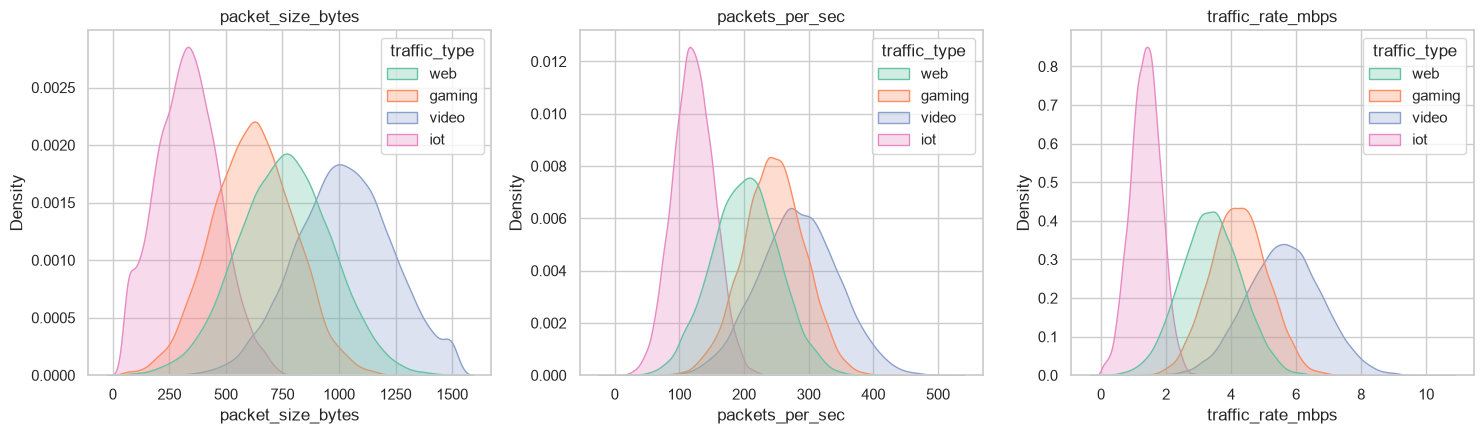

In [4]:
# Distribution of each feature by class
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, f in zip(axes, features):
    sns.kdeplot(data=data, x=f, hue=target, fill=True, alpha=0.3, common_norm=False, ax=ax)
    ax.set_title(f)
plt.tight_layout()
plt.savefig("figures/feature_distributions_by_class.png", dpi=300, bbox_inches="tight")
plt.show()

## 2. Redundancy test

In [5]:
# ---------------------------------------------------------
# REDUNDANCY TEST
# Is traffic_rate_mbps = packet_size_bytes * packets_per_sec * 8 / 1e6 ?
# ---------------------------------------------------------
data["implied_rate_mbps"] = data["packet_size_bytes"] * data["packets_per_sec"] * 8 / 1e6

# 1) Pairwise correlations
corr = data[features].corr()
display(corr.round(3))

# 2) Direct comparison with the deterministic formula
r_implied = data["traffic_rate_mbps"].corr(data["implied_rate_mbps"])
mae = (data["traffic_rate_mbps"] - data["implied_rate_mbps"]).abs().mean()
ratio = data["traffic_rate_mbps"] / data["implied_rate_mbps"]
print(f"Correlation(rate, size*pps*8/1e6): {r_implied:.4f}")
print(f"Mean absolute difference         : {mae:.4f} Mbps")
print("\nRatio rate / implied rate, by class:")
display(ratio.groupby(data[target]).describe().round(3))

# 3) How much of the rate is linearly explained by the other two features
two = ["packet_size_bytes", "packets_per_sec"]
r2_linear = LinearRegression().fit(data[two], data["traffic_rate_mbps"]).score(data[two], data["traffic_rate_mbps"])
print(f"R2 of rate ~ size + pps (linear): {r2_linear:.4f}")

# 4) Variance inflation factor: VIF_i = 1 / (1 - R2_i)
vif = []
for f in features:
    others = [c for c in features if c != f]
    r2 = LinearRegression().fit(data[others], data[f]).score(data[others], data[f])
    vif.append({"feature": f, "R2": r2, "VIF": 1 / (1 - r2)})
vif_df = pd.DataFrame(vif).round(3)
display(vif_df)

# 5) Verdict
if r_implied > 0.99 and mae < 0.05:
    verdict = "DETERMINISTIC: traffic rate is (almost) exactly size*pps*8/1e6 -> feature redundancy. State this in the paper."
elif vif_df["VIF"].max() > 5:
    verdict = "STRONGLY CORRELATED (VIF > 5): not an exact formula, but substantial redundancy. Discuss it."
else:
    verdict = "CORRELATED BUT NOT REDUNDANT: no exact formula and VIF <= 5."
print("\nVERDICT:", verdict)

,packet_size_bytes,packets_per_sec,traffic_rate_mbps
packet_size_bytes,1.000,0.533,0.627
packets_per_sec,0.533,1.000,0.665
traffic_rate_mbps,0.627,0.665,1.000


Correlation(rate, size*pps*8/1e6): 0.6913
Mean absolute difference         : 2.4638 Mbps

Ratio rate / implied rate, by class:


,count,mean,std,min,25%,50%,75%,max
traffic_type,,,,,,,,
gaming,9049.0,4.089,2.509,0.664,2.695,3.558,4.719,48.756
iot,9913.0,5.972,5.468,0.104,2.947,4.465,6.912,108.846
video,16118.0,2.731,3.912,0.382,1.936,2.466,3.175,404.016
web,14920.0,3.291,2.288,0.032,2.048,2.816,3.870,67.172


R2 of rate ~ size + pps (linear): 0.5457


,feature,R2,VIF
0,packet_size_bytes,0.417,1.716
1,packets_per_sec,0.464,1.867
2,traffic_rate_mbps,0.546,2.201



VERDICT: CORRELATED BUT NOT REDUNDANT: no exact formula and VIF <= 5.


## 3. Draft text for the manuscript

In [6]:
# Draft paragraph for the manuscript (Section 6.2), filled with the computed values
r_sp = corr.loc["packet_size_bytes", "packets_per_sec"]
r_sr = corr.loc["packet_size_bytes", "traffic_rate_mbps"]
r_pr = corr.loc["packets_per_sec", "traffic_rate_mbps"]

if r_implied > 0.99 and mae < 0.05:
    redundancy = ("Traffic rate is, to numerical precision, the product of packet size and packet rate "
                  "(packet size x packet rate x 8 / 10^6); it is therefore a deterministic function of the other "
                  "two features and introduces feature redundancy.")
else:
    redundancy = (f"Traffic rate is not an exact function of the other two features: its correlation with the "
                  f"product packet size x packet rate x 8 / 10^6 is {r_implied:.2f}, and a linear model on packet "
                  f"size and packet rate explains R2 = {r2_linear:.2f} of its variance. Pairwise Pearson "
                  f"correlations are r = {r_sp:.2f} (size-packet rate), {r_sr:.2f} (size-traffic rate) and "
                  f"{r_pr:.2f} (packet rate-traffic rate); the maximum VIF is {vif_df['VIF'].max():.2f}.")

print("The dataset contains " + f"{len(data):,}" + " flows distributed across the four classes as follows: "
      + ", ".join(f"{k} {v}%" for k, v in share.items()) + ". "
      "Table X summarizes the per-class profile of the three input features (mean, standard deviation, and "
      "5th-95th percentile range) as measured on the released dataset. " + redundancy)

The dataset contains 50,000 flows distributed across the four classes as follows: video 32.24%, web 29.84%, iot 19.83%, gaming 18.1%. Table X summarizes the per-class profile of the three input features (mean, standard deviation, and 5th-95th percentile range) as measured on the released dataset. Traffic rate is not an exact function of the other two features: its correlation with the product packet size x packet rate x 8 / 10^6 is 0.69, and a linear model on packet size and packet rate explains R2 = 0.55 of its variance. Pairwise Pearson correlations are r = 0.53 (size-packet rate), 0.63 (size-traffic rate) and 0.66 (packet rate-traffic rate); the maximum VIF is 2.20.
